# Practice 14 — RNN for Time Series

**Goal:** read five consecutive trading days with a recurrent layer and predict the next day's closing index.

| Step | What it produces |
|:---|:---|
| Series | KOSPI daily quotes, 431 trading days |
| Windows | five-day input windows and the next-day target |
| Split and scaling | chronological train / validation / test, `StandardScaler` fitted on train |
| Recurrence by hand | a two-day example, then `nn.RNN` on the same numbers |
| `train` / `evaluate` | the epoch loop and the no-grad pass |
| RNN, LSTM | the same output layer and settings → only the recurrent layer differs |
| Comparison | learning curves, predictions in index points, RMSE |

---
## Step 0. Imports and Setup

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

np.random.seed(42)
torch.manual_seed(42)

plt.rcParams['axes.unicode_minus'] = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


---
## Step 1. The Series

- One row per trading day

| Column | Use |
|:---|:---|
| `Open`, `High`, `Low`, `Volume` | model input |
| `Close` | prediction target |
| `Date`, `Adj Close` | not used |

In [2]:
DATA_PATH = './data/kospi.csv'
DATA_URL = 'https://raw.githubusercontent.com/jongmoonha/AI-ME-Practice/main/data/kospi.csv'

if not os.path.exists(DATA_PATH):
    os.makedirs('./data', exist_ok=True)
    print('downloading kospi.csv ...')
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)

print('df', df.shape)

first_date = df['Date'].iloc[0]
last_date = df['Date'].iloc[-1]
print(f'trading days from {first_date} to {last_date}')

df (431, 7)
trading days from 2019-01-30 to 2020-10-30


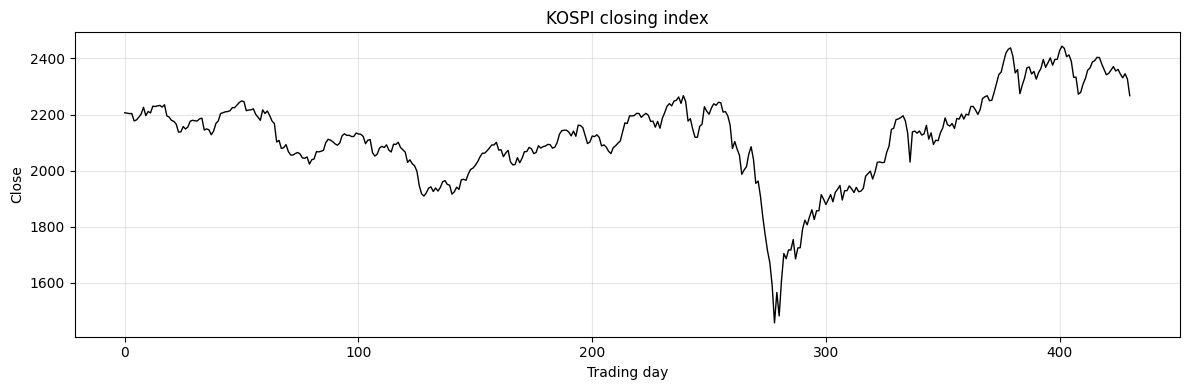

In [3]:
fig, ax = plt.subplots(1, 1, figsize=(12, 4))

ax.plot(df['Close'].values, 'k-', linewidth=1)
ax.set_xlabel('Trading day')
ax.set_ylabel('Close')
ax.set_title('KOSPI closing index')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:
df.head(10)

,Date,Open,High,Low,Close,Adj Close,Volume
0,2019-01-30,2183.489990,2206.199951,2177.879883,2206.199951,2206.199951,480400
1,2019-01-31,2222.879883,2222.879883,2201.219971,2204.850098,2204.850098,545200
2,2019-02-01,2211.929932,2218.780029,2201.409912,2203.459961,2203.459961,479400
3,2019-02-07,2215.770020,2215.790039,2196.770020,2203.419922,2203.419922,427800
4,2019-02-08,2192.010010,2192.479980,2171.959961,2177.050049,2177.050049,391000
5,2019-02-11,2180.540039,2181.580078,2167.360107,2180.729980,2180.729980,406100
6,2019-02-12,2182.709961,2195.050049,2178.590088,2190.469971,2190.469971,429900
7,2019-02-13,2200.000000,2203.709961,2194.750000,2201.479980,2201.479980,422000
8,2019-02-14,2195.919922,2225.850098,2186.090088,2225.850098,2225.850098,573400
9,2019-02-15,2210.939941,2210.939941,2187.709961,2196.090088,2196.090088,400600


---
## Step 2. Sliding Windows

- $T$ days in → the next day's `Close` out

| Tensor | Shape | Meaning |
|:---|:---|:---|
| `X_seq` | `(N, T, d)` | $N$ windows of $T$ days, $d$ features per day |
| `y_seq` | `(N, 1)` | the `Close` of the day after each window |

- $T = 5$, 431 days → $N = 431 - 5 = 426$ windows

In [5]:
sequence_length = 5

X_all = df[['Open', 'High', 'Low', 'Volume']].values.astype(np.float32)
y_all = df[['Close']].values


def to_sequences(X, y, sequence_length):
    # window i covers days i .. i+sequence_length-1 and targets the Close of day i+sequence_length
    X_windows = []
    y_targets = []
    for i in range(len(X) - sequence_length):
        X_windows.append(X[i:i + sequence_length])
        y_targets.append(y[i + sequence_length])
    return np.array(X_windows), np.array(y_targets)


X_seq, y_seq = to_sequences(X_all, y_all, sequence_length)

print(f'X_seq {tuple(X_seq.shape)}   (N, T, d)')
print(f'y_seq {tuple(y_seq.shape)}   (N, 1)')

X_seq (426, 5, 4)   (N, T, d)
y_seq (426, 1)   (N, 1)


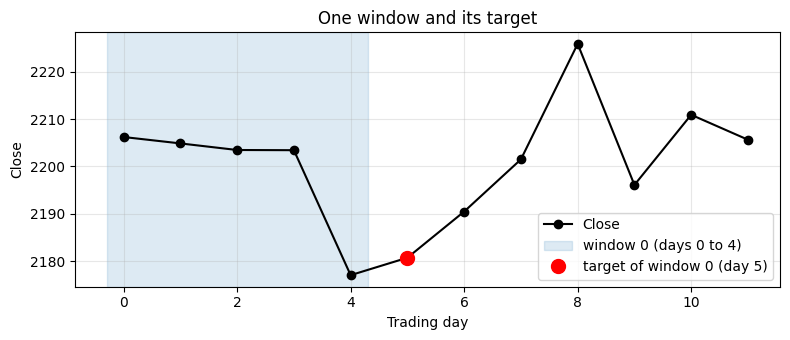

In [6]:
last_day = sequence_length - 1
target_day = sequence_length
days = np.arange(sequence_length + 7)

fig, ax = plt.subplots(1, 1, figsize=(8, 3.5))

ax.plot(days, df['Close'].values[:len(days)], 'ko-', label='Close')
ax.axvspan(-0.3, last_day + 0.3, color='tab:blue', alpha=0.15, label=f'window 0 (days 0 to {last_day})')
ax.plot(target_day, df['Close'].values[target_day], 'ro', markersize=10, label=f'target of window 0 (day {target_day})')
ax.set_xlabel('Trading day')
ax.set_ylabel('Close')
ax.set_title('One window and its target')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- The window feeds the model `Open`, `High`, `Low`, `Volume` of those five days; `Close` is drawn to show which day is predicted

---
## Step 3. Chronological Split and Scaling

| Split | Windows | Share |
|:---|:---|:---|
| Train | 298 | 70% |
| Validation | 63 | 15% |
| Test | 65 | 15% |

- Neighbouring windows share four days → a shuffled split would put near-copies of every test window into training
- Time order → every validation and test window comes after every training window
- `StandardScaler` fitted on the training windows only → applied to all three splits

In [7]:
n_train = int(len(X_seq) * 0.70)
n_val = int(len(X_seq) * 0.15)

X_train, y_train = X_seq[:n_train], y_seq[:n_train]
X_val, y_val = X_seq[n_train:n_train + n_val], y_seq[n_train:n_train + n_val]
X_test, y_test = X_seq[n_train + n_val:], y_seq[n_train + n_val:]

close_train, close_val, close_test = y_train, y_val, y_test     # Close in index points, kept for the error later

input_size = X_seq.shape[2]

# the scaler takes a 2-D table, so the windows are flattened to one row per day and reshaped back
scaler_input = StandardScaler()
scaler_input.fit(X_train.reshape(-1, input_size))
X_train = scaler_input.transform(X_train.reshape(-1, input_size)).reshape(X_train.shape)
X_val = scaler_input.transform(X_val.reshape(-1, input_size)).reshape(X_val.shape)
X_test = scaler_input.transform(X_test.reshape(-1, input_size)).reshape(X_test.shape)

scaler_close = StandardScaler()
scaler_close.fit(y_train)
y_train = scaler_close.transform(y_train)
y_val = scaler_close.transform(y_val)
y_test = scaler_close.transform(y_test)

print(f'windows - train {len(X_train)}, val {len(X_val)}, test {len(X_test)}')
print(f'Close on the training windows - mean {scaler_close.mean_[0]:.2f}, std {scaler_close.scale_[0]:.2f}')
close_train_max = close_train.max()
n_val_above = (close_val > close_train_max).sum()
n_test_above = (close_test > close_train_max).sum()
print(f'training maximum of Close: {close_train_max:.0f}')
print(f'validation windows above it: {n_val_above} of {len(close_val)}')
print(f'test windows above it: {n_test_above} of {len(close_test)}')

windows - train 298, val 63, test 65
Close on the training windows - mean 2077.65, std 140.46
training maximum of Close: 2267
validation windows above it: 0 of 63
test windows above it: 58 of 65


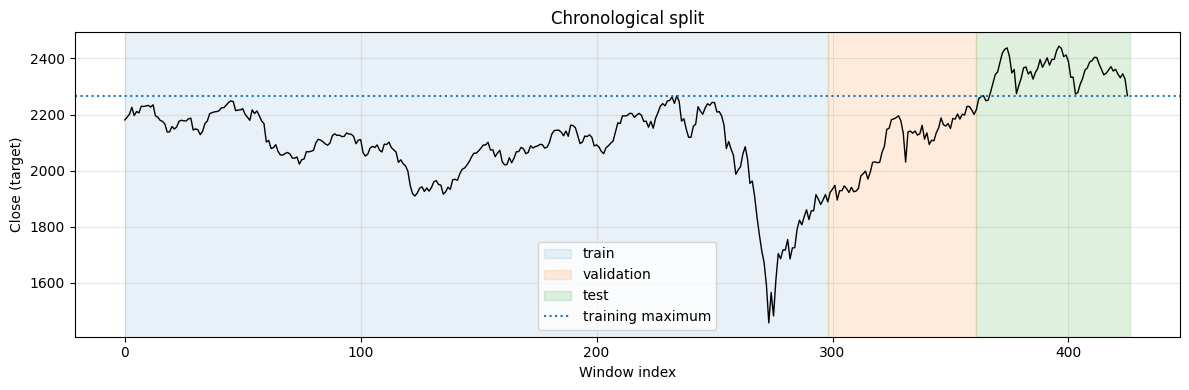

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(12, 4))

ax.plot(y_seq[:, 0], 'k-', linewidth=1)
ax.axvspan(0, n_train, color='tab:blue', alpha=0.10, label='train')
ax.axvspan(n_train, n_train + n_val, color='tab:orange', alpha=0.15, label='validation')
ax.axvspan(n_train + n_val, len(y_seq), color='tab:green', alpha=0.15, label='test')
ax.axhline(close_train_max, color='tab:blue', linestyle=':', label='training maximum')
ax.set_xlabel('Window index')
ax.set_ylabel('Close (target)')
ax.set_title('Chronological split')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- 58 of 65 test targets lie above the training maximum (2,267 points), 0 of 63 validation targets → the test split asks for extrapolation, validation does not

- `train_loader` shuffles the order of the training windows within an epoch; the split itself stays chronological

| Loader | Windows | `shuffle` | Used for |
|:---|:---|:---|:---|
| `train_loader` | train | `True` | the update loop |
| `train_eval_loader` | train | `False` | predictions in time order |
| `val_loader` | validation | `False` | monitoring after each epoch |
| `test_loader` | test | `False` | read once, at the end |

In [9]:
batch_size = 20

X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.FloatTensor(y_train)
X_val_tensor = torch.FloatTensor(X_val)
y_val_tensor = torch.FloatTensor(y_val)
X_test_tensor = torch.FloatTensor(X_test)
y_test_tensor = torch.FloatTensor(y_test)

train_set = TensorDataset(X_train_tensor, y_train_tensor)
val_set = TensorDataset(X_val_tensor, y_val_tensor)
test_set = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
train_eval_loader = DataLoader(train_set, batch_size=batch_size, shuffle=False)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

print(f'batches per epoch - train {len(train_loader)}, val {len(val_loader)}, test {len(test_loader)}')

X_batch, y_batch = next(iter(train_loader))
print(f'one batch - X {tuple(X_batch.shape)}, y {tuple(y_batch.shape)}')

batches per epoch - train 15, val 4, test 4
one batch - X (20, 5, 4), y (20, 1)


---
## Step 4. What a Recurrent Layer Computes

$$\mathbf{h}_t = f\!\left(U\mathbf{x}_t + W\mathbf{h}_{t-1} + \mathbf{b}\right),
\qquad \hat{y}_t = \phi\!\left(V\mathbf{h}_t + c\right),
\qquad t = 1, \dots, T, \qquad \mathbf{h}_0 = \mathbf{0}$$

- $\mathbf{h}_t \in \mathbb{R}^{H}$ → the hidden state ($H$ = `hidden_size`), updated once per time step
- Same $U$, $W$ at every step → that is what makes the layer recurrent
- $V$ reads the state out → the final linear layer

### A Two-Day Example by Hand

| | $x_1$ (yesterday) | $x_2$ (today) | $\hat{y}_2$ (tomorrow) |
|:---|:---|:---|:---|
| Sequence 1 | 0 | 0.5 | ≈ 1 |
| Sequence 2 | 1 | 0.5 | 0 |

- $U = 1.8$, $W = -0.5$, $V = 1.1$, no biases, $f$ = ReLU, $\phi$ = identity, $\mathbf{h}_0 = 0$
- $d = H = 1$ → every quantity is a scalar
- Same today, different yesterday → the state $\mathbf{h}_1$ carries yesterday into tomorrow's prediction

In [10]:
U = 1.8
W = -0.5
V = 1.1

X_example = torch.tensor([[[0.0], [0.5]],
                          [[1.0], [0.5]]])      # two sequences of two days, (N, T, d) = (2, 2, 1)

for n in [1, 2]:
    h = 0.0
    print(f'sequence {n}')
    for t in [1, 2]:
        x_t = X_example[n - 1, t - 1, 0].item()
        h = max(U * x_t + W * h, 0.0)       # f = ReLU
        y_hat = V * h                       # phi = identity
        print(f'  t = {t}: x = {x_t:.1f}, h = {h:.2f}, y_hat = {y_hat:.2f}')

sequence 1
  t = 1: x = 0.0, h = 0.00, y_hat = 0.00
  t = 2: x = 0.5, h = 0.90, y_hat = 0.99
sequence 2
  t = 1: x = 1.0, h = 1.80, y_hat = 1.98
  t = 2: x = 0.5, h = 0.00, y_hat = 0.00


In [11]:
rnn_example = nn.RNN(input_size=1, hidden_size=1, nonlinearity='relu', batch_first=True)
fc_example = nn.Linear(1, 1)

with torch.no_grad():
    rnn_example.weight_ih_l0.fill_(U)       # U
    rnn_example.weight_hh_l0.fill_(W)       # W
    rnn_example.bias_ih_l0.zero_()
    rnn_example.bias_hh_l0.zero_()
    fc_example.weight.fill_(V)              # V
    fc_example.bias.zero_()

    out_example, h_n_example = rnn_example(X_example)     # h_0 defaults to zeros
    y_hat_example = fc_example(out_example)

print('h_1, h_2 per sequence (nn.RNN):')
print(out_example[:, :, 0].numpy())
print('h_T alone (h_n):')
print(h_n_example[0, :, 0].numpy())
print('y_hat_1, y_hat_2 per sequence (nn.Linear on top):')
print(y_hat_example[:, :, 0].numpy())

h_1, h_2 per sequence (nn.RNN):
[[0.  0.9]
 [1.8 0. ]]
h_T alone (h_n):
[0.9 0. ]
y_hat_1, y_hat_2 per sequence (nn.Linear on top):
[[0.   0.99]
 [1.98 0.  ]]


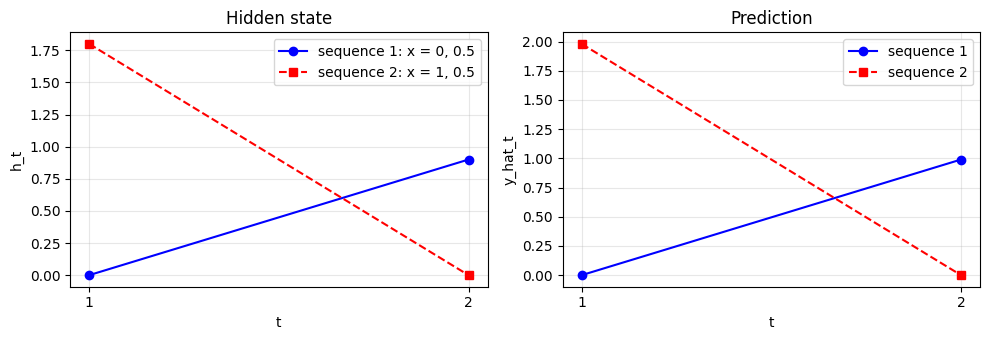

In [12]:
steps = [1, 2]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(steps, out_example[0, :, 0].numpy(), 'bo-', label='sequence 1: x = 0, 0.5')
axes[0].plot(steps, out_example[1, :, 0].numpy(), 'rs--', label='sequence 2: x = 1, 0.5')
axes[0].set_xticks(steps)
axes[0].set_xlabel('t')
axes[0].set_ylabel('h_t')
axes[0].set_title('Hidden state')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(steps, y_hat_example[0, :, 0].numpy(), 'bo-', label='sequence 1')
axes[1].plot(steps, y_hat_example[1, :, 0].numpy(), 'rs--', label='sequence 2')
axes[1].set_xticks(steps)
axes[1].set_xlabel('t')
axes[1].set_ylabel('y_hat_t')
axes[1].set_title('Prediction')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Sequence 1 ends at 0.99, sequence 2 at 0 → the same numbers as the loop by hand
- `out_example` holds every $\mathbf{h}_t$, `h_n_example` the last one; the same yesterday-today pair ends in opposite states

### The Same Recurrence with Matrices

| Symbol | Shape | Parameter |
|:---|:---|:---|
| $U$ | `(H, d)` | `weight_ih_l0` |
| $W$ | `(H, H)` | `weight_hh_l0` |
| $\mathbf{b}$ | `(H,)` | `bias_ih_l0 + bias_hh_l0` |
| $V$ | `(1, H)` | `fc.weight` |
| $c$ | `(1,)` | `fc.bias` |

- `ih` = input to hidden, `hh` = hidden to hidden; PyTorch keeps two bias vectors where the equation has one → the loop below adds both
- $f$ = $\tanh$ from here on, the `nn.RNN` default; `hidden_size` and `num_layers` set below are the sizes every model uses

In [13]:
hidden_size = 8
num_layers = 1

torch.manual_seed(42)
rnn_demo = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)

print('U', tuple(rnn_demo.weight_ih_l0.shape))
print('W', tuple(rnn_demo.weight_hh_l0.shape))
print('b', tuple(rnn_demo.bias_ih_l0.shape), tuple(rnn_demo.bias_hh_l0.shape))

X_window = X_train_tensor[0:1]                          # a single window, (1, T, d)
h0 = torch.zeros(num_layers, 1, hidden_size)            # h_0 = 0, one per layer and per window: (num_layers, N, H)

with torch.no_grad():
    out, h_n = rnn_demo(X_window, h0)

# the same recurrence written out one time step at a time
h = torch.zeros(hidden_size)
with torch.no_grad():
    for t in range(sequence_length):
        x_t = X_window[0, t]
        h = torch.tanh(rnn_demo.weight_ih_l0 @ x_t + rnn_demo.weight_hh_l0 @ h
                       + rnn_demo.bias_ih_l0 + rnn_demo.bias_hh_l0)      # U x_t + W h_{t-1} + b

print(f'out {tuple(out.shape)} holds h_1 .. h_T, h_n {tuple(h_n.shape)} holds h_T alone')
print('by hand :', h.numpy())
print('nn.RNN  :', out[0, -1].numpy())

U (8, 4)
W (8, 8)
b (8,) (8,)
out (1, 5, 8) holds h_1 .. h_T, h_n (1, 1, 8) holds h_T alone
by hand : [ 0.5033831  -0.50472003 -0.09631947  0.00760637 -0.31599468 -0.3569225
  0.10617596 -0.1379918 ]
nn.RNN  : [ 0.5033831  -0.50472003 -0.09631941  0.00760631 -0.31599465 -0.3569225
  0.10617593 -0.13799182]


- The two lines agree to float32 precision → `nn.RNN` is this loop

---
## Step 5. `train` and `evaluate`

| Function | Returns |
|:---|:---|
| `evaluate(model, loader, device)` | `(loss, y_pred)` |
| `train(model, train_loader, val_loader, optimizer, epochs, device)` | `(train_losses, val_losses)` |

- `loss` → mean of the per-batch MSEs on standardized targets, what the learning curves plot
- The error in index points comes from `y_pred` after training, with `scaler_close.inverse_transform`
- Shared settings below: $\rho$ (learning rate), epochs, Adam, MSE

In [14]:
def evaluate(model, loader, device):
    model.eval()
    criterion = nn.MSELoss()
    loss_sum = 0.0
    preds = []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            y_hat = model(X_batch)
            loss_sum += criterion(y_hat, y_batch).item()
            preds.append(y_hat.cpu())

    loss = loss_sum / len(loader)
    y_pred = torch.cat(preds).numpy()
    return loss, y_pred

In [15]:
def train(model, train_loader, val_loader, optimizer, epochs, device):
    criterion = nn.MSELoss()
    train_losses, val_losses = [], []
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = 0.0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            y_hat = model(X_batch)
            loss = criterion(y_hat, y_batch)

            optimizer.zero_grad()                 # clear the accumulated gradients
            loss.backward()                       # autograd computes the gradients
            optimizer.step()                      # the optimizer updates the parameters

            loss_sum += loss.item()

        train_loss = loss_sum / len(train_loader)
        val_loss, _ = evaluate(model, val_loader, device)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if epoch % 50 == 0:
            print(f'  Epoch {epoch:3d}/{epochs}  train MSE={train_loss:.4f}  val MSE={val_loss:.4f}')
    return train_losses, val_losses

In [16]:
rho = 1e-3
epochs = 200

print(f'Sequence length : {sequence_length}')
print(f'Hidden size     : {hidden_size}')
print(f'Recurrent layers: {num_layers}')
print(f'Batch size      : {batch_size}')
print(f'Learning rate   : {rho}')
print(f'Epochs          : {epochs}')
print('Optimizer       : Adam')
print('Loss            : MSELoss')

Sequence length : 5
Hidden size     : 8
Recurrent layers: 1
Batch size      : 20
Learning rate   : 0.001
Epochs          : 200
Optimizer       : Adam
Loss            : MSELoss


---
## Step 6. RNN

$$\hat{y} = V\mathbf{h}_T + c, \qquad V \in \mathbb{R}^{1 \times H}$$

- `self.rnn` → the recurrent layer of Step 4; `self.fc` → $V$ and $c$ (`fc.weight`, `fc.bias`); $\phi$ is the identity for regression
- The readout sees only $\mathbf{h}_T$, the state after all $T$ days

In [17]:
class RNNRegressor(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=x.device)   # h_0 = 0
        out, h_n = self.rnn(x, h0)      # out holds h_1 .. h_T for every window in the batch
        y_hat = self.fc(out[:, -1, :])  # V h_T + c, the last time step only
        return y_hat

In [18]:
torch.manual_seed(42)
model_rnn = RNNRegressor(input_size, hidden_size, num_layers).to(device)
optimizer_rnn = optim.Adam(model_rnn.parameters(), lr=rho)

n_params_rnn = sum(p.numel() for p in model_rnn.parameters())
print(f'parameters: {n_params_rnn}')

torch.manual_seed(42)   # train_loader shuffles from the same state for every model
train_losses_rnn, val_losses_rnn = train(model_rnn, train_loader, val_loader, optimizer_rnn, epochs, device)

parameters: 121


  Epoch  50/200  train MSE=0.0539  val MSE=0.0440


  Epoch 100/200  train MSE=0.0399  val MSE=0.0312


  Epoch 150/200  train MSE=0.0364  val MSE=0.0324


  Epoch 200/200  train MSE=0.0330  val MSE=0.0310


In [19]:
_, y_pred_train_rnn = evaluate(model_rnn, train_eval_loader, device)
_, y_pred_val_rnn = evaluate(model_rnn, val_loader, device)
_, y_pred_test_rnn = evaluate(model_rnn, test_loader, device)

close_pred_train_rnn = scaler_close.inverse_transform(y_pred_train_rnn)
close_pred_val_rnn = scaler_close.inverse_transform(y_pred_val_rnn)
close_pred_test_rnn = scaler_close.inverse_transform(y_pred_test_rnn)

rmse_train_rnn = root_mean_squared_error(close_train, close_pred_train_rnn)
rmse_val_rnn = root_mean_squared_error(close_val, close_pred_val_rnn)
rmse_test_rnn = root_mean_squared_error(close_test, close_pred_test_rnn)

print(f'RNN   RMSE (index points) - train {rmse_train_rnn:6.1f}, val {rmse_val_rnn:6.1f}, test {rmse_test_rnn:6.1f}')

RNN   RMSE (index points) - train   25.2, val   27.7, test   63.8


---
## Step 7. LSTM

- Same output layer, same settings → only `nn.RNN` becomes `nn.LSTM`
- Two states travel from step to step: the cell state $\mathbf{C}_t$ (long-term) and the hidden state $\mathbf{h}_t$ (short-term)

| Gate | Decides |
|:---|:---|
| forget | how much of the previous cell state to keep |
| input | how much of the candidate cell state to write |
| output | how much of the cell state to show as the hidden state |

- Three gates and the candidate, each with its own $U$, $W$, $\mathbf{b}$ → `weight_ih_l0` is `(4H, d)`, about four times the parameters

In [20]:
class LSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=x.device)   # h_0 = 0
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=x.device)   # C_0 = 0
        out, (h_n, c_n) = self.lstm(x, (h0, c0))   # out holds h_1 .. h_T, as in RNNRegressor
        y_hat = self.fc(out[:, -1, :])             # V h_T + c
        return y_hat

In [21]:
torch.manual_seed(42)
model_lstm = LSTMRegressor(input_size, hidden_size, num_layers).to(device)
optimizer_lstm = optim.Adam(model_lstm.parameters(), lr=rho)

n_params_lstm = sum(p.numel() for p in model_lstm.parameters())
print(f'parameters: {n_params_lstm}')
print('weight_ih_l0', tuple(model_lstm.lstm.weight_ih_l0.shape), '  (4H, d) - four blocks stacked: input gate, forget gate, candidate, output gate')

torch.manual_seed(42)   # train_loader shuffles from the same state for every model
train_losses_lstm, val_losses_lstm = train(model_lstm, train_loader, val_loader, optimizer_lstm, epochs, device)

parameters: 457
weight_ih_l0 (32, 4)   (4H, d) - four blocks stacked: input gate, forget gate, candidate, output gate


  Epoch  50/200  train MSE=0.0571  val MSE=0.0808


  Epoch 100/200  train MSE=0.0414  val MSE=0.0534


  Epoch 150/200  train MSE=0.0344  val MSE=0.0608


  Epoch 200/200  train MSE=0.0287  val MSE=0.0706


In [22]:
_, y_pred_train_lstm = evaluate(model_lstm, train_eval_loader, device)
_, y_pred_val_lstm = evaluate(model_lstm, val_loader, device)
_, y_pred_test_lstm = evaluate(model_lstm, test_loader, device)

close_pred_train_lstm = scaler_close.inverse_transform(y_pred_train_lstm)
close_pred_val_lstm = scaler_close.inverse_transform(y_pred_val_lstm)
close_pred_test_lstm = scaler_close.inverse_transform(y_pred_test_lstm)

rmse_train_lstm = root_mean_squared_error(close_train, close_pred_train_lstm)
rmse_val_lstm = root_mean_squared_error(close_val, close_pred_val_lstm)
rmse_test_lstm = root_mean_squared_error(close_test, close_pred_test_lstm)

print(f'LSTM  RMSE (index points) - train {rmse_train_lstm:6.1f}, val {rmse_val_lstm:6.1f}, test {rmse_test_lstm:6.1f}')

LSTM  RMSE (index points) - train   23.5, val   41.7, test   67.3


---
## Step 8. Comparison

| Item | RNN | LSTM |
|:---|:---|:---|
| Recurrent layer | `nn.RNN`, $\tanh$ | `nn.LSTM`, three gates and a cell state |
| Readout | `nn.Linear(hidden_size, 1)` on `out[:, -1, :]` | same |
| $H$, layers, $T$, batch size | 8, 1, 5, 20 | same |
| Data, split, scaling, loaders | shared objects from Step 3 | same |
| $\rho$, epochs, optimizer, loss | shared values from Step 5 | same |
| Seed before construction (initial weights) and before training (shuffle order) | 42 | 42 |

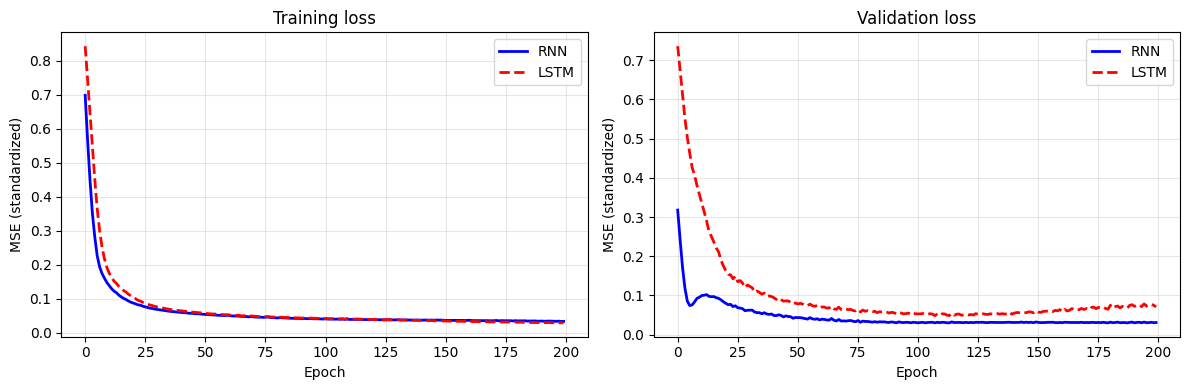

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_losses_rnn, 'b-', linewidth=2, label='RNN')
axes[0].plot(train_losses_lstm, 'r--', linewidth=2, label='LSTM')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE (standardized)')
axes[0].set_title('Training loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(val_losses_rnn, 'b-', linewidth=2, label='RNN')
axes[1].plot(val_losses_lstm, 'r--', linewidth=2, label='LSTM')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MSE (standardized)')
axes[1].set_title('Validation loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Training curves nearly coincide (MSE 0.033 vs 0.029 at epoch 200); on validation the RNN settles near 0.031 while the LSTM turns up after epoch 100 (0.053 → 0.071)
- The LSTM keeps improving on the training windows while its validation loss rises → it fits them at the validation windows' expense; no early stopping here, the numbers below are the epoch-200 models

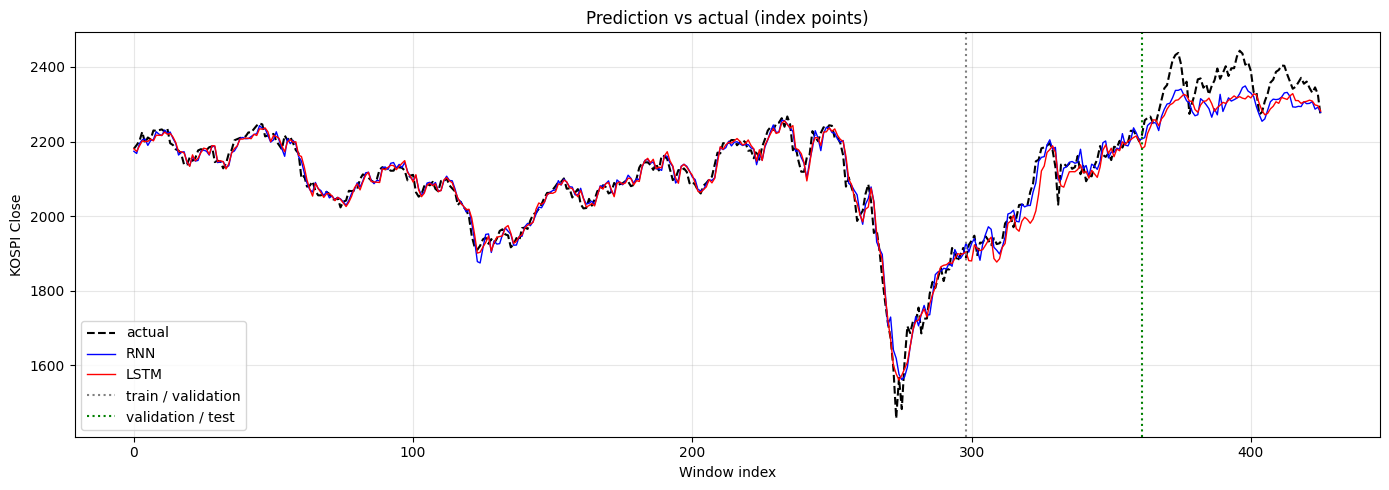

In [24]:
# the three splits are already in time order, so concatenating them rebuilds the whole series
close_pred_rnn = np.concatenate([close_pred_train_rnn, close_pred_val_rnn, close_pred_test_rnn])
close_pred_lstm = np.concatenate([close_pred_train_lstm, close_pred_val_lstm, close_pred_test_lstm])
close_actual = np.concatenate([close_train, close_val, close_test])

fig, ax = plt.subplots(1, 1, figsize=(14, 5))

ax.plot(close_actual[:, 0], 'k--', linewidth=1.5, label='actual')
ax.plot(close_pred_rnn[:, 0], 'b-', linewidth=1, label='RNN')
ax.plot(close_pred_lstm[:, 0], 'r-', linewidth=1, label='LSTM')
ax.axvline(n_train, color='gray', linestyle=':', label='train / validation')
ax.axvline(n_train + n_val, color='green', linestyle=':', label='validation / test')
ax.set_xlabel('Window index')
ax.set_ylabel('KOSPI Close')
ax.set_title('Prediction vs actual (index points)')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Inside the training range both follow the series; in the test stretch both fall short of the peaks: the extrapolation counted in Step 3

In [25]:
pd.DataFrame([
    {'model': 'RNN', 'parameters': n_params_rnn, 'train RMSE': rmse_train_rnn, 'val RMSE': rmse_val_rnn, 'test RMSE': rmse_test_rnn},
    {'model': 'LSTM', 'parameters': n_params_lstm, 'train RMSE': rmse_train_lstm, 'val RMSE': rmse_val_lstm, 'test RMSE': rmse_test_lstm},
]).round(1)

,model,parameters,train RMSE,val RMSE,test RMSE
0,RNN,121,25.2,27.7,63.8
1,LSTM,457,23.5,41.7,67.3


- Validation, inside the fitted range → RNN 27.7 vs LSTM 41.7 points: the comparison to trust
- Test → 63.8 vs 67.3, reported for completeness: it measures drift outside the fitted range, so model choice uses validation
- Another GPU or a CPU shifts these numbers a little; the ordering on validation is what to read
- Whether the gates help depends on the series and the window → Exercise 2 lengthens the window

### Optional — GRU

- Two gates (reset, update) instead of three, no separate cell state → `nn.GRU`, the rest unchanged

In [26]:
class GRURegressor(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=x.device)   # h_0 = 0
        out, h_n = self.gru(x, h0)      # out holds h_1 .. h_T, as in RNNRegressor
        y_hat = self.fc(out[:, -1, :])  # V h_T + c
        return y_hat


torch.manual_seed(42)
model_gru = GRURegressor(input_size, hidden_size, num_layers).to(device)
optimizer_gru = optim.Adam(model_gru.parameters(), lr=rho)

n_params_gru = sum(p.numel() for p in model_gru.parameters())
print(f'parameters: {n_params_gru}')

torch.manual_seed(42)
train_losses_gru, val_losses_gru = train(model_gru, train_loader, val_loader, optimizer_gru, epochs, device)

_, y_pred_val_gru = evaluate(model_gru, val_loader, device)
_, y_pred_test_gru = evaluate(model_gru, test_loader, device)

close_pred_val_gru = scaler_close.inverse_transform(y_pred_val_gru)
close_pred_test_gru = scaler_close.inverse_transform(y_pred_test_gru)

rmse_val_gru = root_mean_squared_error(close_val, close_pred_val_gru)
rmse_test_gru = root_mean_squared_error(close_test, close_pred_test_gru)

print(f'GRU   RMSE (index points) - val {rmse_val_gru:6.1f}, test {rmse_test_gru:6.1f}')

parameters: 345


  Epoch  50/200  train MSE=0.0587  val MSE=0.0600


  Epoch 100/200  train MSE=0.0385  val MSE=0.0407


  Epoch 150/200  train MSE=0.0351  val MSE=0.0416


  Epoch 200/200  train MSE=0.0320  val MSE=0.0415
GRU   RMSE (index points) - val   31.5, test   93.5


- GRU → 345 parameters; validation 31.5 points, test 93.5 in this run

### Optional — Reading All Hidden States

$$\hat{y} = V\left[\mathbf{h}_1; \mathbf{h}_2; \dots; \mathbf{h}_T\right] + c, \qquad V \in \mathbb{R}^{1 \times HT}$$

- The readout sees every $\mathbf{h}_t$ laid end to end instead of $\mathbf{h}_T$ alone → $HT + 1 = 41$ readout weights instead of $H + 1 = 9$
- The recurrent layer is the RNN of Step 6, untouched

In [27]:
class RNNAllStates(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, sequence_length):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size * sequence_length, 1)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=x.device)   # h_0 = 0
        out, h_n = self.rnn(x, h0)                        # h_1 .. h_T
        y_hat = self.fc(out.reshape(out.size(0), -1))     # all time steps, laid end to end
        return y_hat


torch.manual_seed(42)
model_states = RNNAllStates(input_size, hidden_size, num_layers, sequence_length).to(device)
optimizer_states = optim.Adam(model_states.parameters(), lr=rho)

torch.manual_seed(42)
train_losses_states, val_losses_states = train(model_states, train_loader, val_loader, optimizer_states, epochs, device)

_, y_pred_val_states = evaluate(model_states, val_loader, device)
_, y_pred_test_states = evaluate(model_states, test_loader, device)

close_pred_val_states = scaler_close.inverse_transform(y_pred_val_states)
close_pred_test_states = scaler_close.inverse_transform(y_pred_test_states)

rmse_val_states = root_mean_squared_error(close_val, close_pred_val_states)
rmse_test_states = root_mean_squared_error(close_test, close_pred_test_states)

print(f'RNN, all states  RMSE (index points) - val {rmse_val_states:6.1f}, test {rmse_test_states:6.1f}')

  Epoch  50/200  train MSE=0.0548  val MSE=0.0551


  Epoch 100/200  train MSE=0.0410  val MSE=0.0496


  Epoch 150/200  train MSE=0.0359  val MSE=0.0547


  Epoch 200/200  train MSE=0.0326  val MSE=0.0521
RNN, all states  RMSE (index points) - val   36.0, test   36.7


- Validation 36.0 points → worse than reading $\mathbf{h}_T$ alone (27.7): inside the fitted range the last state suffices; test 36.7 is reported, not compared

---
## Summary

- Same $U$, $W$ at every step → that is the recurrence; the two-day example and the matrix loop both match `nn.RNN`
- Windows are split in time order and standardized on training statistics; the test split lies above the training range, so validation decides
- Only the recurrent layer differs → on validation the RNN (27.7 points) beats the LSTM (41.7); the gates did not pay off on five-day windows

---
## Exercises

1. `num_layers = 2`, retrain the RNN and the LSTM — both classes read the same variable; the matrix loop of Step 4 covers one layer.
2. `sequence_length = 40`, rerun from Step 2 — what happens to the training loss?
3. Add `Close` to the input columns, retrain — does yesterday's level change the test error?
4. Predict the day-to-day change in `Close`, not its level.

In [28]:
# Write your code here